<a href="https://colab.research.google.com/github/nkhanhhh/CausalForest_Uplift_Criteo/blob/main/CausalForest_Uplift_Criteo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Causal Forest dự đoán uplift cho chiến dịch quảng cáo (dữ liệu Criteo)

Notebook này là bước **Python** trong luồng *GA4 → BigQuery → Python → Power BI*: huấn luyện mô hình uplift, đánh giá, phân nhóm khách hàng và xuất file CSV để dựng dashboard Power BI.

| | |
|---|---|
| **Dữ liệu** | Criteo Uplift ([Kaggle: arashnic/uplift-modeling](https://www.kaggle.com/datasets/arashnic/uplift-modeling)): ~14 triệu dòng, 12 đặc trưng ẩn danh `f0`–`f11`, `treatment` (1 = được quảng cáo, 0 = nhóm đối chứng), `visit`, `conversion`, `exposure` |
| **Mô hình chính** | Causal Forest (`CausalForestDML`, thư viện EconML) |
| **Mô hình so sánh** | T-Learner (2 mô hình LightGBM) |
| **Đánh giá** | Qini curve, uplift curve, AUUC, Qini AUC, uplift@k, uplift theo decile |
| **Đầu ra** | Thư mục `powerbi_output/` (CSV cho Power BI) và `figures/` (hình cho báo cáo), gói trong `ket_qua_uplift.zip` |

**Cách chạy:** mở bằng Google Colab → *Runtime → Run all*. Lần chạy đầu có thể mất 10–20 phút (gồm tải và đọc khoảng 3 GB dữ liệu). Nếu chạy quá lâu, giảm `N_SAMPLE` ở mục 2.

## 1. Cài thư viện
`econml` (tự cài kèm `lightgbm`) và `kagglehub` để tải dữ liệu. Nếu Colab hiện nút **Restart session** sau khi cài, bấm restart rồi chạy tiếp từ ô ngay bên dưới.

In [1]:
%pip install -q econml kagglehub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 32.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.3/155.3 kB 5.2 MB/s eta 0:00:00


## 2. Cấu hình
- `OUTCOME = "visit"` được khuyên dùng: tỷ lệ visit khoảng 4–5% nên tín hiệu uplift rõ. `conversion` chỉ khoảng 0,3% nên kết quả nhiễu hơn nhiều (khi đó nên tăng `N_SAMPLE`).
- `COST_PER_CONTACT` và `VALUE_PER_OUTCOME` là **giả định để minh hoạ** phần mô phỏng chi phí/lợi nhuận. Thay bằng số liệu thực tế nếu có.

In [2]:
import os, time, glob, gzip, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

warnings.filterwarnings("ignore")   # ẩn các cảnh báo không ảnh hưởng kết quả

# ---- Dữ liệu & mô hình ----
OUTCOME      = "visit"      # "visit" (khuyên dùng) hoặc "conversion"
N_SAMPLE     = 500_000      # số dòng lấy mẫu từ ~14 triệu dòng (chạy chậm thì giảm xuống 200_000)
TEST_SIZE    = 0.3          # 30% làm tập kiểm tra
N_TREES      = 200          # số cây của Causal Forest (phải chia hết cho 4)
MIN_LEAF     = 200          # số mẫu tối thiểu mỗi lá: lớn hơn → uplift mượt và ổn định hơn
ALPHA        = 0.05         # mức ý nghĩa → khoảng tin cậy 95%
RANDOM_STATE = 42
DATA_PATH    = None         # None = tự tải từ Kaggle; hoặc đường dẫn tới file criteo-uplift-v2.1.csv

# ---- Giả định kinh doanh (thay bằng số thực tế nếu có) ----
COST_PER_CONTACT  = 0.01                                  # chi phí quảng cáo cho 1 khách ($)
VALUE_PER_OUTCOME = 1.5 if OUTCOME == "visit" else 15.0   # giá trị của 1 visit/conversion tăng thêm ($)
N_CUSTOMERS       = 100_000                               # quy mô chiến dịch dùng để mô phỏng
BREAKEVEN         = COST_PER_CONTACT / VALUE_PER_OUTCOME  # uplift tối thiểu để quảng cáo có lãi

# ---- Thư mục đầu ra ----
OUTPUT_DIR, FIG_DIR = "powerbi_output", "figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

FEATURES = [f"f{i}" for i in range(12)]
LABELS   = ["treatment", "conversion", "visit", "exposure"]

def pp(x):
    """Định dạng uplift theo điểm phần trăm, ví dụ 0.0123 → '+1.23 điểm %'."""
    return f"{x * 100:+.2f} điểm %"

print(f"Outcome: {OUTCOME} | Mẫu: {N_SAMPLE:,} dòng | Uplift hoà vốn: {pp(BREAKEVEN)}")

Outcome: visit | Mẫu: 500,000 dòng | Uplift hoà vốn: +0.67 điểm %


In [3]:
# Màu và kiểu chung cho mọi biểu đồ
C_CF, C_TL, C_RAND = "#2a78d6", "#eb6834", "#898781"   # Causal Forest, T-Learner, chọn ngẫu nhiên
C_MUTED, C_INK, C_INK2, C_BG = "#c3c2b7", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": C_BG, "axes.facecolor": C_BG, "savefig.facecolor": C_BG,
    "axes.edgecolor": C_MUTED, "axes.labelcolor": C_INK2, "axes.titlecolor": C_INK,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": C_MUTED, "ytick.color": C_MUTED, "xtick.labelcolor": C_INK2, "ytick.labelcolor": C_INK2,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2, "figure.dpi": 110,
})

def save_fig(fig, name):
    """Lưu hình vào thư mục figures/ để chèn vào báo cáo."""
    fig.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

## 3. Tải và lấy mẫu dữ liệu
Notebook tự tải dữ liệu từ Kaggle bằng `kagglehub` (dataset công khai, thường không cần đăng nhập). Nếu bước này lỗi:
- chạy `import kagglehub; kagglehub.login()` rồi chạy lại ô này, **hoặc**
- tải file `criteo-uplift-v2.1.csv` từ Kaggle, đưa lên Google Drive rồi gán đường dẫn vào `DATA_PATH` ở mục 2.

File gốc có khoảng 14 triệu dòng nên notebook đọc theo từng khối (chunk) và lấy mẫu ngẫu nhiên `N_SAMPLE` dòng để không bị tràn RAM.

In [4]:
def find_csv(folder):
    """Tìm file CSV lớn nhất trong thư mục (file dữ liệu chính)."""
    files = glob.glob(os.path.join(folder, "**", "*.csv*"), recursive=True)
    if not files:
        raise FileNotFoundError(f"Không tìm thấy file CSV trong {folder}")
    return max(files, key=os.path.getsize)

if DATA_PATH is None:
    import kagglehub
    DATA_PATH = find_csv(kagglehub.dataset_download("arashnic/uplift-modeling"))
print(f"File dữ liệu: {DATA_PATH} ({os.path.getsize(DATA_PATH) / 1e9:.2f} GB)")

100%|██████████| 324M/324M [00:05<00:00, 67.7MB/s]

Extracting files...


File dữ liệu: /root/.cache/kagglehub/datasets/arashnic/uplift-modeling/versions/1/criteo-uplift-v2.1.csv (3.25 GB)


In [5]:
def count_rows(path):
    """Đếm số dòng dữ liệu (không tính dòng tiêu đề) mà không nạp cả file vào RAM."""
    opener = gzip.open if path.endswith(".gz") else open
    with opener(path, "rb") as f:
        return sum(block.count(b"\n") for block in iter(lambda: f.read(1 << 24), b"")) - 1

t0 = time.time()
header = pd.read_csv(DATA_PATH, nrows=0).columns
lower = {c: c.strip().lower() for c in header}
missing = sorted(set(FEATURES + LABELS) - set(lower.values()))
if missing:
    raise ValueError(f"File thiếu cột {missing}. Các cột hiện có: {list(header)}")
usecols = [c for c in header if lower[c] in FEATURES + LABELS]
dtypes = {c: ("float32" if lower[c] in FEATURES else "int8") for c in usecols}

print("Đang đọc và lấy mẫu dữ liệu (1–3 phút)...")
n_rows = count_rows(DATA_PATH)
keep_prob = min(1.0, 1.05 * N_SAMPLE / n_rows)      # lấy dư 5% rồi cắt đúng N_SAMPLE
rng = np.random.default_rng(RANDOM_STATE)
parts = [chunk[rng.random(len(chunk)) < keep_prob]
         for chunk in pd.read_csv(DATA_PATH, usecols=usecols, dtype=dtypes, chunksize=1_000_000)]
df = pd.concat(parts, ignore_index=True).rename(columns=lower)
if len(df) > N_SAMPLE:
    df = df.sample(n=N_SAMPLE, random_state=RANDOM_STATE).reset_index(drop=True)
df.insert(0, "customer_id", np.arange(len(df)))
print(f"File có {n_rows:,} dòng → lấy mẫu {len(df):,} dòng ({time.time() - t0:.0f}s)")
df.head()

Đang đọc và lấy mẫu dữ liệu (1–3 phút)...
File có 13,979,592 dòng → lấy mẫu 500,000 dòng (71s)


,customer_id,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,0,20.806206,10.059654,8.214383,4.679882,10.280525,4.115453,-5.987667,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
1,1,12.616364,10.059654,8.668047,4.679882,10.280525,4.115453,0.294443,4.833815,3.920995,22.570330,5.300375,-0.168679,1,0,0,0
2,2,23.088852,10.059654,8.214383,4.679882,10.280525,4.115453,-2.411115,4.833815,3.971858,13.190056,5.300375,-0.168679,1,0,0,0
3,3,12.616364,10.059654,8.214383,4.679882,10.280525,3.013064,0.294443,10.022961,3.971858,13.190056,5.300375,-0.168679,1,0,0,0
4,4,24.314260,10.059654,8.214383,4.679882,10.280525,4.115453,-5.987667,4.833815,3.971858,13.190056,5.300375,-0.168679,1,0,0,0


## 4. Khám phá nhanh
Criteo là dữ liệu **A/B test ngẫu nhiên**: khoảng 85% khách được quảng cáo (treatment), 15% không (control). Vì chia ngẫu nhiên nên chênh lệch tỷ lệ visit giữa hai nhóm chính là **hiệu ứng trung bình (ATE)** của quảng cáo.

**Lưu ý:** cột `exposure` (khách có thực sự nhìn thấy quảng cáo hay không) chỉ biết được **sau khi** quảng cáo chạy, nên **không được dùng làm đặc trưng**. Dùng nó sẽ gây rò rỉ dữ liệu (data leakage).

In [6]:
def rate_diff_ci(y, t, alpha=ALPHA):
    """Chênh lệch tỷ lệ outcome giữa treatment và control, kèm khoảng tin cậy."""
    p1, p0 = y[t == 1].mean(), y[t == 0].mean()
    se = np.sqrt(p1 * (1 - p1) / (t == 1).sum() + p0 * (1 - p0) / (t == 0).sum())
    z = norm.ppf(1 - alpha / 2)
    return p1 - p0, p1 - p0 - z * se, p1 - p0 + z * se

by_group = (df.groupby("treatment")
              .agg(so_khach=("customer_id", "size"), ty_le_visit=("visit", "mean"),
                   ty_le_conversion=("conversion", "mean"), ty_le_exposure=("exposure", "mean"))
              .rename(index={0: "Control", 1: "Treatment"}))
display(by_group.style.format({"so_khach": "{:,}", "ty_le_visit": "{:.2%}",
                               "ty_le_conversion": "{:.3%}", "ty_le_exposure": "{:.2%}"}))

ate, ate_lo, ate_hi = rate_diff_ci(df[OUTCOME].to_numpy(), df["treatment"].to_numpy())
print(f"Tỷ lệ khách được quảng cáo (treatment): {df['treatment'].mean():.1%}")
print(f"ATE của quảng cáo lên {OUTCOME}: {pp(ate)}  (khoảng tin cậy {1 - ALPHA:.0%}: {pp(ate_lo)} → {pp(ate_hi)})")

,so_khach,ty_le_visit,ty_le_conversion,ty_le_exposure
treatment,,,,
Control,"74,737",3.64%,0.171%,0.00%
Treatment,"425,263",4.81%,0.308%,3.55%


Tỷ lệ khách được quảng cáo (treatment): 85.1%
ATE của quảng cáo lên visit: +1.17 điểm %  (khoảng tin cậy 95%: +1.02 điểm % → +1.32 điểm %)


## 5. Chia tập huấn luyện / kiểm tra
Chia 70/30 và giữ nguyên tỷ lệ treatment, outcome ở cả hai tập. Tập kiểm tra chỉ dùng để đánh giá và xuất kết quả cho Power BI.

In [7]:
from sklearn.model_selection import train_test_split

X = df[FEATURES].to_numpy(dtype=np.float64)
y = df[OUTCOME].to_numpy(dtype=np.int64)
t = df["treatment"].to_numpy(dtype=np.int64)
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=TEST_SIZE,
                                       random_state=RANDOM_STATE, stratify=t * 2 + y)
X_train, X_test = X[idx_train], X[idx_test]
y_train, y_test = y[idx_train], y[idx_test]
t_train, t_test = t[idx_train], t[idx_test]
ate_test = y_test[t_test == 1].mean() - y_test[t_test == 0].mean()
print(f"Train: {len(idx_train):,} dòng | Test: {len(idx_test):,} dòng | ATE trên tập test: {pp(ate_test)}")

Train: 350,000 dòng | Test: 150,000 dòng | ATE trên tập test: +1.17 điểm %


## 6. Mô hình so sánh: T-Learner (LightGBM)
T-Learner huấn luyện **2 mô hình riêng**: một mô hình trên nhóm treatment để dự đoán P(visit | có quảng cáo), một mô hình trên nhóm control để dự đoán P(visit | không quảng cáo). Uplift là hiệu của hai xác suất này. Đây là cách làm phổ biến nhất nên được dùng làm mốc so sánh với Causal Forest.

In [8]:
from lightgbm import LGBMClassifier

LGBM_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=200,
                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                   random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)

t0 = time.time()
model_treat = LGBMClassifier(**LGBM_PARAMS).fit(X_train[t_train == 1], y_train[t_train == 1])
model_ctrl  = LGBMClassifier(**LGBM_PARAMS).fit(X_train[t_train == 0], y_train[t_train == 0])
p_treat_test = model_treat.predict_proba(X_test)[:, 1]   # P(visit | có quảng cáo)
p_ctrl_test  = model_ctrl.predict_proba(X_test)[:, 1]    # P(visit | không quảng cáo), dùng lại ở mục 10
uplift_tl = p_treat_test - p_ctrl_test
time_tl = time.time() - t0
print(f"T-Learner: {time_tl:.0f}s | uplift dự đoán trung bình {pp(uplift_tl.mean())}")

T-Learner: 19s | uplift dự đoán trung bình +0.92 điểm %


## 7. Mô hình chính: Causal Forest (`CausalForestDML`)
Causal Forest (Wager & Athey, 2018) cũng là một rừng cây, nhưng khác Random Forest thông thường ở ba điểm:

- **Chia nhánh theo uplift:** mỗi lần chia chọn cách tách sao cho uplift của hai nhóm con **khác nhau nhiều nhất**, thay vì để dự đoán visit chính xác nhất.
- **Honest:** mỗi cây dùng một nửa dữ liệu để chọn cách chia và nửa còn lại để ước lượng uplift trong từng lá. Nhờ vậy mô hình hạn chế overfit và tính được **khoảng tin cậy** cho uplift của từng khách hàng.
- **Double Machine Learning (DML):** trước khi dựng rừng, hai mô hình phụ (LightGBM) dự đoán `visit` và `treatment` từ các đặc trưng; rừng học trên phần dư (residual) của hai dự đoán đó. Cách này loại bỏ ảnh hưởng của đặc trưng lên cả outcome lẫn việc được quảng cáo, nên dùng được cả với dữ liệu không phải A/B test (như GA4), với điều kiện đã có đủ các biến gây nhiễu.

Đầu ra cho mỗi khách hàng: uplift τ(x) = P(visit | có quảng cáo) − P(visit | không quảng cáo), kèm khoảng tin cậy 95%.

In [9]:
from econml.dml import CausalForestDML

print("Đang huấn luyện Causal Forest (có thể mất vài phút)...")
t0 = time.time()
cf = CausalForestDML(
    model_y=LGBMClassifier(**{**LGBM_PARAMS, "n_estimators": 200}),   # mô hình phụ: P(visit | x)
    model_t=LGBMClassifier(**{**LGBM_PARAMS, "n_estimators": 200}),   # mô hình phụ: P(treatment | x)
    discrete_outcome=True,       # outcome nhị phân (0/1)
    discrete_treatment=True,     # treatment nhị phân (0/1)
    cv=3,                        # cross-fitting 3 phần cho hai mô hình phụ
    n_estimators=N_TREES,
    min_samples_leaf=MIN_LEAF,
    max_samples=0.25,            # mỗi cây dùng 25% dữ liệu (phải ≤ 0.5 để tính được khoảng tin cậy)
    honest=True,
    inference=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
cf.fit(y_train, t_train, X=X_train)
uplift_cf = cf.effect(X_test, T0=0, T1=1).ravel()   # effect() trả về mảng (n, 1) khi discrete_outcome=True → làm phẳng về (n,)
ci_low, ci_high = cf.effect_interval(X_test, T0=0, T1=1, alpha=ALPHA)
time_cf = time.time() - t0
print(f"Causal Forest: {time_cf:.0f}s | uplift dự đoán trung bình {pp(uplift_cf.mean())}")
print(f"Khách có uplift dương chắc chắn (cận dưới CI {1 - ALPHA:.0%} > 0): {(ci_low > 0).mean():.1%}")

Đang huấn luyện Causal Forest (có thể mất vài phút)...
Causal Forest: 222s | uplift dự đoán trung bình +0.81 điểm %
Khách có uplift dương chắc chắn (cận dưới CI 95% > 0): 20.8%


## 8. Đánh giá trên tập kiểm tra
Không đo được uplift của từng người (mỗi khách chỉ thuộc treatment **hoặc** control), nên uplift được đánh giá theo nhóm: xếp khách theo uplift dự đoán giảm dần, rồi kiểm tra xem nhóm đứng đầu có thực sự chênh lệch treatment − control lớn hơn không.

- **Uplift curve (cumulative gain):** số visit tăng thêm nếu chỉ quảng cáo cho top k% khách.
- **Qini curve:** tương tự, nhưng quy đổi theo số khách trong nhóm treatment (Radcliffe, 2007).
- **AUUC / Qini AUC (chuẩn hoá):** phần diện tích giữa đường của mô hình và đường chọn ngẫu nhiên, chia cho phần diện tích của mô hình lý tưởng. 0 nghĩa là không hơn chọn ngẫu nhiên, 1 là hoàn hảo (cùng công thức với thư viện scikit-uplift).
- **Uplift@k:** chênh lệch tỷ lệ visit treatment − control **thực tế** trong top k% khách.

In [10]:
from sklearn.metrics import auc

def _cumulative(y, t, score):
    """Cộng dồn theo uplift dự đoán giảm dần; các điểm có cùng score được gộp lại."""
    order = np.argsort(-score, kind="mergesort")
    y, t, score = y[order].astype(float), t[order].astype(float), score[order]
    ends = np.r_[np.flatnonzero(np.diff(score)), len(score) - 1]
    n = ends + 1.0
    n_t = np.cumsum(t)[ends]
    y_t = np.cumsum(y * t)[ends]
    y_c = np.cumsum(y * (1 - t))[ends]
    return n, n_t, n - n_t, y_t, y_c

def _div(a, b):
    return np.divide(a, b, out=np.zeros_like(a), where=b != 0)

def qini_curve(y, t, score):
    n, n_t, n_c, y_t, y_c = _cumulative(y, t, score)
    return np.r_[0, n], np.r_[0, y_t - y_c * _div(n_t, n_c)]

def uplift_curve(y, t, score):
    n, n_t, n_c, y_t, y_c = _cumulative(y, t, score)
    return np.r_[0, n], np.r_[0, (_div(y_t, n_t) - _div(y_c, n_c)) * n]

def _normalized_area(curve, y, t, score, perfect_score):
    x, v = curve(y, t, score)
    xp, vp = curve(y, t, perfect_score)
    random_area = auc([0, xp[-1]], [0, vp[-1]])
    return (auc(x, v) - random_area) / (auc(xp, vp) - random_area)

def qini_auc_score(y, t, score):
    perfect = y * t - y * (1 - t)                      # thứ tự lý tưởng
    return _normalized_area(qini_curve, y, t, score, perfect.astype(float))

def uplift_auc_score(y, t, score):
    ctrl_resp = np.sum((y == 1) & (t == 0))
    treat_nonresp = np.sum((y == 0) & (t == 1))
    perfect = 2 * (y == t) + (y if ctrl_resp > treat_nonresp else t)   # thứ tự lý tưởng
    return _normalized_area(uplift_curve, y, t, score, perfect.astype(float))

def uplift_at_k(y, t, score, k):
    top = np.argsort(-score, kind="mergesort")[: int(len(score) * k)]
    return y[top][t[top] == 1].mean() - y[top][t[top] == 0].mean()

In [11]:
models = {"Causal Forest": uplift_cf, "T-Learner": uplift_tl}
rows = []
for name, score in models.items():
    rows.append({"model": name,
                 "auuc": uplift_auc_score(y_test, t_test, score),
                 "qini_auc": qini_auc_score(y_test, t_test, score),
                 "uplift_at_10": uplift_at_k(y_test, t_test, score, 0.1),
                 "uplift_at_20": uplift_at_k(y_test, t_test, score, 0.2),
                 "uplift_at_30": uplift_at_k(y_test, t_test, score, 0.3),
                 "train_time_s": time_cf if name == "Causal Forest" else time_tl})
rows.append({"model": "Ngẫu nhiên", "auuc": 0.0, "qini_auc": 0.0, "uplift_at_10": ate_test,
             "uplift_at_20": ate_test, "uplift_at_30": ate_test, "train_time_s": 0.0})
metrics = pd.DataFrame(rows)
display(metrics.style.format({"auuc": "{:.3f}", "qini_auc": "{:.3f}", "uplift_at_10": "{:+.2%}",
                              "uplift_at_20": "{:+.2%}", "uplift_at_30": "{:+.2%}", "train_time_s": "{:.0f}"})
               .hide(axis="index"))

model,auuc,qini_auc,uplift_at_10,uplift_at_20,uplift_at_30,train_time_s
Causal Forest,0.037,0.096,+6.90%,+4.38%,+3.31%,222
T-Learner,0.023,0.059,+5.98%,+3.68%,+2.64%,19
Ngẫu nhiên,0.000,0.000,+1.17%,+1.17%,+1.17%,0


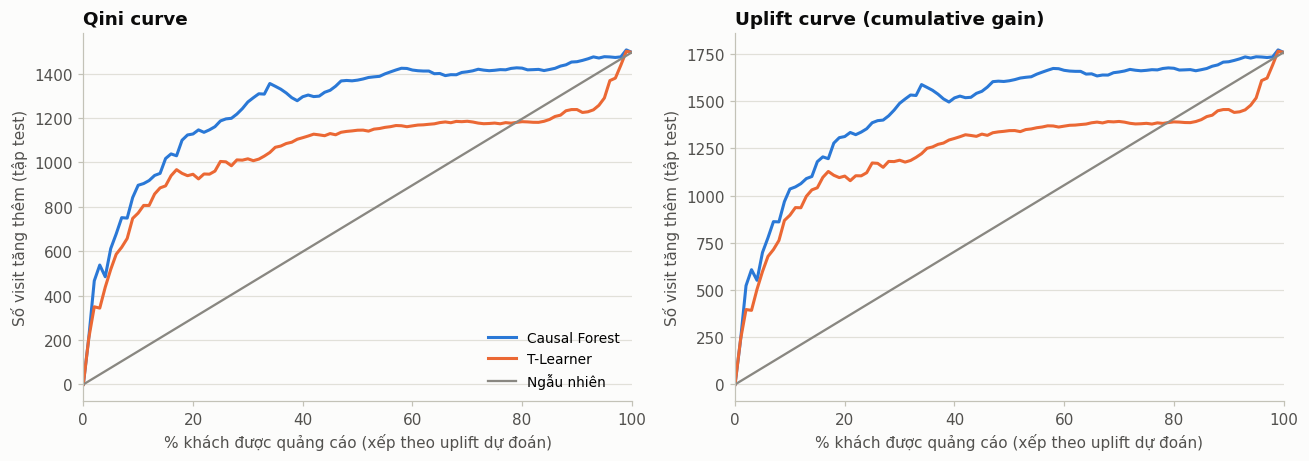

In [12]:
grid = np.linspace(0, 1, 101)          # 0%, 1%, ..., 100% khách được quảng cáo

def on_grid(curve, score):
    x, v = curve(y_test, t_test, score)
    return np.interp(grid, x / x[-1], v)

curves = {name: {"qini": on_grid(qini_curve, s), "uplift": on_grid(uplift_curve, s)} for name, s in models.items()}
curves["Ngẫu nhiên"] = {key: grid * curves["Causal Forest"][key][-1] for key in ("qini", "uplift")}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, key, title in zip(axes, ["qini", "uplift"], ["Qini curve", "Uplift curve (cumulative gain)"]):
    for name, color in [("Causal Forest", C_CF), ("T-Learner", C_TL), ("Ngẫu nhiên", C_RAND)]:
        ax.plot(grid * 100, curves[name][key], color=color, label=name,
                linewidth=1.5 if name == "Ngẫu nhiên" else 2)
    ax.set_title(title)
    ax.set_xlabel("% khách được quảng cáo (xếp theo uplift dự đoán)")
    ax.set_ylabel(f"Số {OUTCOME} tăng thêm (tập test)")
    ax.set_xlim(0, 100)
axes[0].legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "qini_uplift_curves.png")
plt.show()

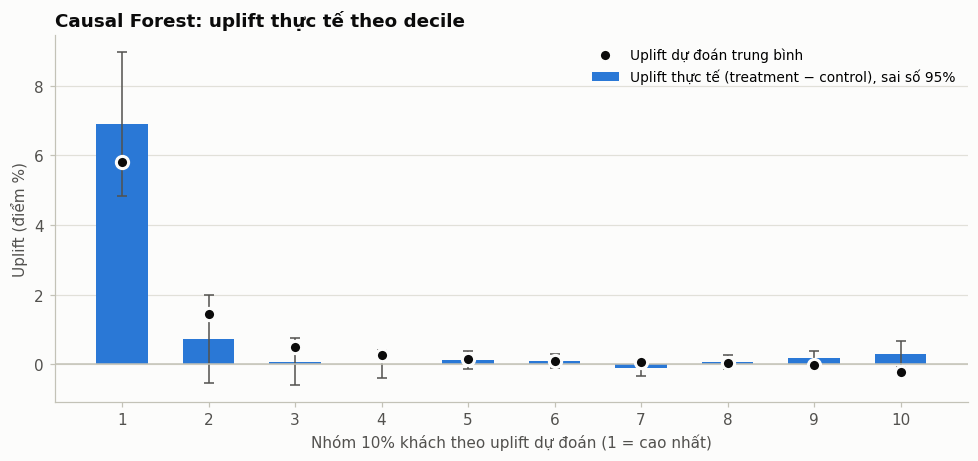

,decile,n,n_treatment,n_control,rate_treatment,rate_control,actual_uplift,actual_uplift_se,predicted_uplift
0,1,15000,13004,1996,0.3255,0.2565,0.0690,0.0106,0.0580
1,2,15000,12777,2223,0.0927,0.0855,0.0073,0.0065,0.0143
2,3,15000,12685,2315,0.0245,0.0238,0.0008,0.0035,0.0049
3,4,15000,12780,2220,0.0081,0.0081,0.0000,0.0021,0.0025
4,5,15000,12683,2317,0.0042,0.0030,0.0012,0.0013,0.0015
5,6,15000,12695,2305,0.0026,0.0017,0.0009,0.0010,0.0009
6,7,15000,12749,2251,0.0015,0.0027,-0.0012,0.0011,0.0006
7,8,15000,12740,2260,0.0024,0.0018,0.0007,0.0010,0.0003
8,9,15000,12732,2268,0.0038,0.0022,0.0016,0.0011,-0.0002
9,10,15000,12734,2266,0.0095,0.0066,0.0029,0.0019,-0.0023


In [13]:
def uplift_by_decile(y, t, score, n_bins=10):
    """Uplift thực tế (treatment − control) và uplift dự đoán trong từng nhóm 10% khách."""
    d = pd.DataFrame({"y": y, "t": t, "score": score})
    d["decile"] = pd.qcut(d["score"].rank(method="first", ascending=False), n_bins, labels=False) + 1
    g1, g0 = d[d.t == 1].groupby("decile")["y"], d[d.t == 0].groupby("decile")["y"]
    out = pd.DataFrame({"n_treatment": g1.size(), "n_control": g0.size(),
                        "rate_treatment": g1.mean(), "rate_control": g0.mean()})
    out["actual_uplift"] = out.rate_treatment - out.rate_control
    out["actual_uplift_se"] = np.sqrt(out.rate_treatment * (1 - out.rate_treatment) / out.n_treatment
                                      + out.rate_control * (1 - out.rate_control) / out.n_control)
    out["predicted_uplift"] = d.groupby("decile")["score"].mean()
    out.insert(0, "n", out.n_treatment + out.n_control)
    return out.rename_axis("decile").reset_index()

dec_cf = uplift_by_decile(y_test, t_test, uplift_cf)
z = norm.ppf(1 - ALPHA / 2)
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.bar(dec_cf.decile, dec_cf.actual_uplift * 100, width=0.6, color=C_CF,
       yerr=z * dec_cf.actual_uplift_se * 100, error_kw=dict(ecolor=C_INK2, elinewidth=1, capsize=3),
       label=f"Uplift thực tế (treatment − control), sai số {1 - ALPHA:.0%}")
ax.scatter(dec_cf.decile, dec_cf.predicted_uplift * 100, s=64, color=C_INK, edgecolor=C_BG,
           linewidth=2, zorder=3, label="Uplift dự đoán trung bình")
ax.axhline(0, color=C_MUTED, linewidth=1)
ax.set_xticks(range(1, 11))
ax.set_xlabel("Nhóm 10% khách theo uplift dự đoán (1 = cao nhất)")
ax.set_ylabel("Uplift (điểm %)")
ax.set_title("Causal Forest: uplift thực tế theo decile")
ax.legend(loc="upper right")
fig.tight_layout()
save_fig(fig, "uplift_by_decile.png")
plt.show()
display(dec_cf.round(4))

## 9. Giải thích mô hình
- **Mức quan trọng của đặc trưng** trong Causal Forest cho biết đặc trưng nào làm uplift **khác nhau giữa các khách**, không phải đặc trưng dự đoán visit tốt nhất.
- **Cây giải thích** (`SingleTreeCateInterpreter`): một cây nông học lại từ uplift dự đoán, cho thấy các nhóm khách có uplift cao/thấp theo các luật dễ đọc.

Criteo đã ẩn danh các đặc trưng (`f0`–`f11`), nên báo cáo chỉ nêu được tên đặc trưng quan trọng, không diễn giải được ý nghĩa kinh doanh của chúng.

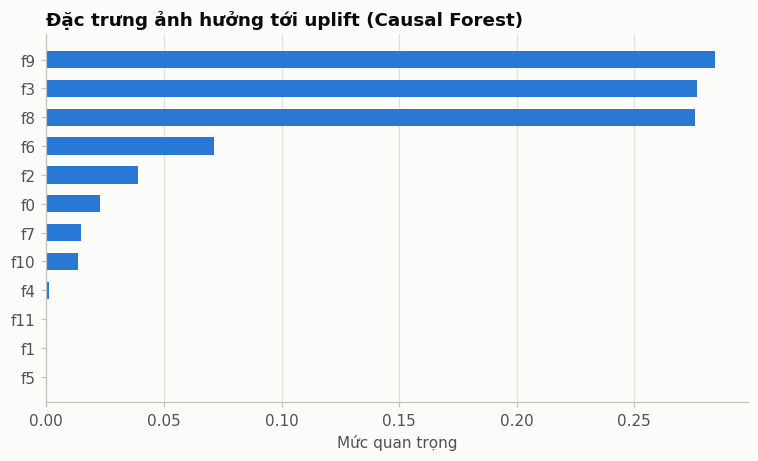

In [14]:
fi = (pd.DataFrame({"feature": FEATURES, "importance": cf.feature_importances_})
        .sort_values("importance", ascending=False, ignore_index=True))
fig, ax = plt.subplots(figsize=(7, 4.3))
ax.barh(fi.feature[::-1], fi.importance[::-1], color=C_CF, height=0.6)
ax.grid(False)
ax.grid(True, axis="x")
ax.set_xlabel("Mức quan trọng")
ax.set_title("Đặc trưng ảnh hưởng tới uplift (Causal Forest)")
fig.tight_layout()
save_fig(fig, "feature_importance.png")
plt.show()

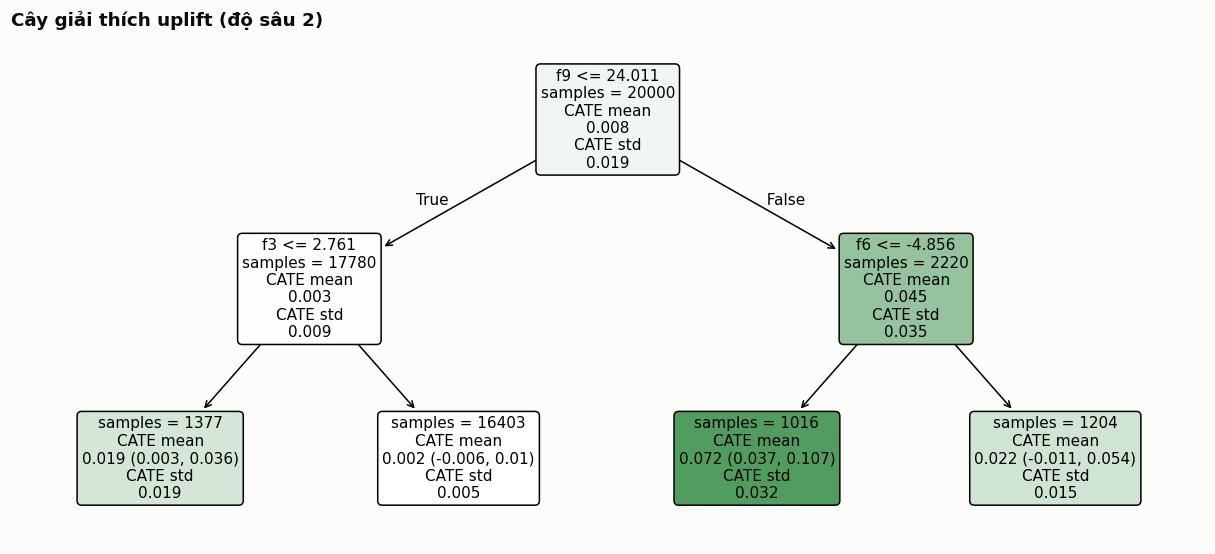

In [15]:
from econml.cate_interpreter import SingleTreeCateInterpreter

sample = np.random.default_rng(RANDOM_STATE).choice(len(X_test), size=min(20_000, len(X_test)), replace=False)
try:
    interp = SingleTreeCateInterpreter(include_model_uncertainty=True, max_depth=2, min_samples_leaf=1_000)
    interp.interpret(cf, X_test[sample])
    fig, ax = plt.subplots(figsize=(14, 6))
    interp.plot(ax=ax, feature_names=FEATURES, fontsize=10)
    ax.set_title("Cây giải thích uplift (độ sâu 2)")
    save_fig(fig, "uplift_tree.png")
    plt.show()
except Exception as e:                  # phần phụ: lỗi ở đây không ảnh hưởng các bước sau
    print("Không vẽ được cây giải thích:", e)

## 10. Phân 4 nhóm khách hàng
Kết hợp uplift dự đoán, khoảng tin cậy (Causal Forest) và xác suất visit khi **không** quảng cáo (`p_control`, từ mô hình control của T-Learner):

| Nhóm | Điều kiện | Hành động |
|---|---|---|
| **Persuadables** | uplift ≥ mức hoà vốn (`COST_PER_CONTACT / VALUE_PER_OUTCOME`) | Nên quảng cáo |
| **Do-Not-Disturb** | cận trên khoảng tin cậy < 0 (chắc chắn quảng cáo gây tác dụng ngược) | Không quảng cáo |
| **Sure Things** | các khách còn lại có `p_control` ≥ tỷ lệ visit trung bình của nhóm control | Không cần quảng cáo |
| **Lost Causes** | các khách còn lại có `p_control` thấp hơn mức đó | Không đáng đầu tư |

Cột `actual_uplift` trong bảng tóm tắt là uplift **thực tế** (treatment − control) đo trên tập kiểm tra, dùng để kiểm chứng cách phân nhóm.

segment,n_customers,share,avg_predicted_uplift,avg_p_control,actual_uplift
Persuadables,"31,845",21.2%,+3.45%,15.85%,+4.17%
Sure Things,"3,910",2.6%,+0.16%,11.12%,+0.25%
Lost Causes,"114,245",76.2%,+0.09%,0.32%,+0.08%
Do-Not-Disturb,0,0.0%,–,–,–


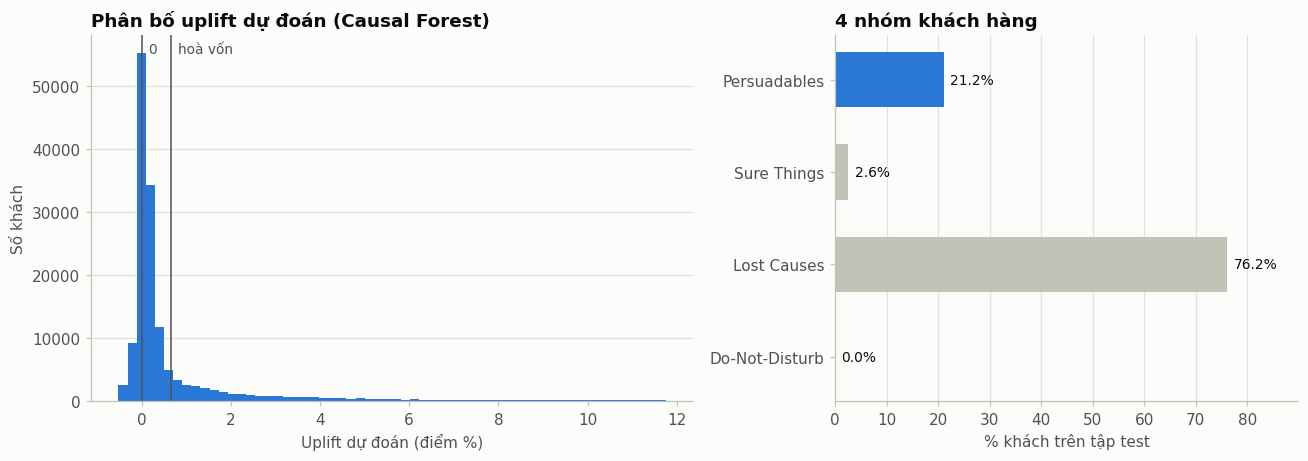

In [16]:
SEGMENTS = ["Persuadables", "Sure Things", "Lost Causes", "Do-Not-Disturb"]
base_rate = y_test[t_test == 0].mean()
segment = np.select([uplift_cf >= BREAKEVEN, ci_high < 0, p_ctrl_test >= base_rate],
                    ["Persuadables", "Do-Not-Disturb", "Sure Things"], default="Lost Causes")

rows = []
for s in SEGMENTS:
    m = segment == s
    has_both = (t_test[m] == 1).any() and (t_test[m] == 0).any()
    rows.append({"segment": s, "n_customers": int(m.sum()), "share": m.mean(),
                 "avg_predicted_uplift": uplift_cf[m].mean() if m.any() else np.nan,
                 "avg_p_control": p_ctrl_test[m].mean() if m.any() else np.nan,
                 "actual_uplift": (y_test[m & (t_test == 1)].mean() - y_test[m & (t_test == 0)].mean())
                                  if has_both else np.nan})
segment_summary = pd.DataFrame(rows)
display(segment_summary.style.format({"n_customers": "{:,}", "share": "{:.1%}", "avg_predicted_uplift": "{:+.2%}",
                                      "avg_p_control": "{:.2%}", "actual_uplift": "{:+.2%}"}, na_rep="–")
                       .hide(axis="index"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.3, 1]})
lo, hi = np.percentile(uplift_cf, [0.5, 99.5]) * 100          # bỏ 1% giá trị cực trị cho dễ nhìn
ax1.hist(uplift_cf * 100, bins=60, range=(lo, hi), color=C_CF)
for x, text in [(0, "0"), (BREAKEVEN * 100, "hoà vốn")]:
    ax1.axvline(x, color=C_INK2, linewidth=1)
    ax1.annotate(text, (x, 1), xycoords=("data", "axes fraction"), xytext=(4, -12),
                 textcoords="offset points", color=C_INK2, fontsize=9)
ax1.set_xlabel("Uplift dự đoán (điểm %)")
ax1.set_ylabel("Số khách")
ax1.set_title("Phân bố uplift dự đoán (Causal Forest)")

colors = [C_CF if s == "Persuadables" else C_MUTED for s in SEGMENTS]
ax2.barh(SEGMENTS[::-1], segment_summary.share[::-1] * 100, color=colors[::-1], height=0.6)
for i, v in enumerate(segment_summary.share[::-1] * 100):
    ax2.annotate(f"{v:.1f}%", (v, i), xytext=(4, 0), textcoords="offset points",
                 va="center", color=C_INK, fontsize=9)
ax2.grid(False)
ax2.grid(True, axis="x")
ax2.set_xlim(0, max(segment_summary.share * 100) * 1.18)
ax2.set_xlabel("% khách trên tập test")
ax2.set_title("4 nhóm khách hàng")
fig.tight_layout()
save_fig(fig, "segments.png")
plt.show()

## 11. Mô phỏng chiến dịch: nên quảng cáo cho bao nhiêu % khách?
Giả sử chiến dịch có `N_CUSTOMERS` khách và chỉ quảng cáo cho top k% khách có uplift dự đoán cao nhất:

**lợi nhuận tăng thêm = `VALUE_PER_OUTCOME` × số visit tăng thêm − `COST_PER_CONTACT` × số khách được quảng cáo**

Số visit tăng thêm lấy từ uplift curve **thực tế** trên tập kiểm tra, quy đổi theo tỷ lệ về `N_CUSTOMERS` khách. Kết quả phụ thuộc vào hai giả định chi phí và giá trị ở mục 2.

Tốt nhất: quảng cáo cho top 34% khách → lợi nhuận tăng thêm $1,248 (quảng cáo cho tất cả: $759) trên 100,000 khách


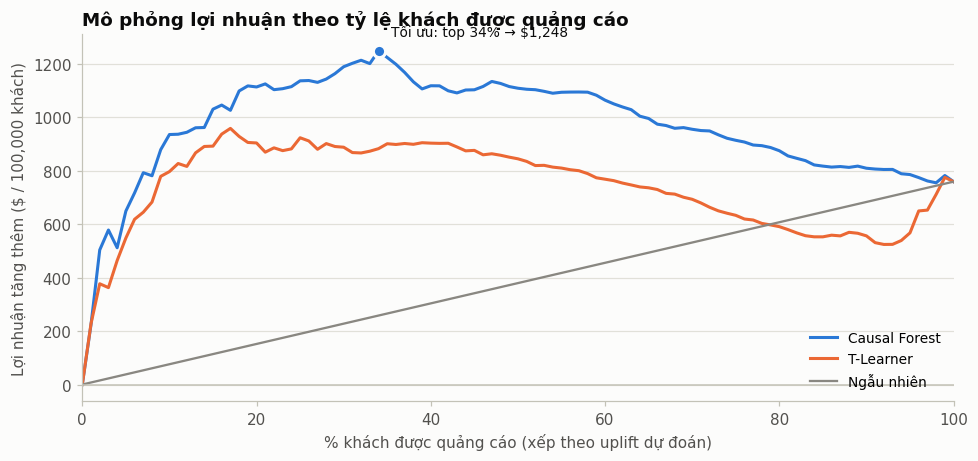

In [17]:
n_test = len(y_test)
campaign = pd.concat([
    pd.DataFrame({"model": name,
                  "pct_targeted": np.round(grid * 100).astype(int),
                  "n_targeted": np.round(grid * N_CUSTOMERS).astype(int),
                  "incremental_outcomes": curves[name]["uplift"] / n_test * N_CUSTOMERS})
    for name in ["Causal Forest", "T-Learner", "Ngẫu nhiên"]], ignore_index=True)
campaign["revenue"] = VALUE_PER_OUTCOME * campaign.incremental_outcomes
campaign["cost"] = COST_PER_CONTACT * campaign.n_targeted
campaign["profit"] = campaign.revenue - campaign.cost

cf_sim = campaign[campaign.model == "Causal Forest"].set_index("pct_targeted")
best_pct = int(cf_sim.profit.idxmax())
best_profit, all_profit = cf_sim.profit[best_pct], cf_sim.profit[100]
print(f"Tốt nhất: quảng cáo cho top {best_pct}% khách → lợi nhuận tăng thêm ${best_profit:,.0f} "
      f"(quảng cáo cho tất cả: ${all_profit:,.0f}) trên {N_CUSTOMERS:,} khách")

fig, ax = plt.subplots(figsize=(9, 4.3))
for name, color in [("Causal Forest", C_CF), ("T-Learner", C_TL), ("Ngẫu nhiên", C_RAND)]:
    d = campaign[campaign.model == name]
    ax.plot(d.pct_targeted, d.profit, color=color, label=name, linewidth=1.5 if name == "Ngẫu nhiên" else 2)
ax.axhline(0, color=C_MUTED, linewidth=1)
ax.scatter([best_pct], [best_profit], s=64, color=C_CF, edgecolor=C_BG, linewidth=2, zorder=3)
right = best_pct > 60                   # đặt nhãn phía trái điểm nếu điểm nằm sát mép phải
ax.annotate(f"Tối ưu: top {best_pct}% → ${best_profit:,.0f}", (best_pct, best_profit),
            xytext=(-8 if right else 8, 10), textcoords="offset points",
            ha="right" if right else "left", color=C_INK, fontsize=9)
ax.set_xlim(0, 100)
ax.set_xlabel("% khách được quảng cáo (xếp theo uplift dự đoán)")
ax.set_ylabel(f"Lợi nhuận tăng thêm ($ / {N_CUSTOMERS:,} khách)")
ax.set_title("Mô phỏng lợi nhuận theo tỷ lệ khách được quảng cáo")
ax.legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "campaign_profit.png")
plt.show()

## 12. Xuất dữ liệu cho Power BI

| File | Nội dung | Visual gợi ý |
|---|---|---|
| `overview.csv` | Số khách, tỷ lệ visit/conversion theo nhóm, ATE, kết quả mô phỏng | Card |
| `model_metrics.csv` | AUUC, Qini AUC, uplift@k của các mô hình | Table |
| `uplift_curves.csv` | Qini và uplift curve (dạng dài: model × % khách) | Line chart, Legend = `model` |
| `uplift_by_decile.csv` | Uplift thực tế và dự đoán theo decile, cho cả 2 mô hình | Clustered column |
| `customer_uplift_scores.csv` | Uplift, khoảng tin cậy, nhóm của từng khách (tập test) | Table + slicer theo `segment` |
| `segment_summary.csv` | Quy mô và uplift thực tế của 4 nhóm | Bar / donut |
| `campaign_simulation.csv` | Lợi nhuận theo % khách được quảng cáo | Line chart |
| `feature_importance.csv` | Mức quan trọng của đặc trưng | Bar chart |

Trong Power BI: *Get data → Text/CSV* cho từng file, hoặc *Get data → Folder* để nạp cả thư mục. Muốn đổi giả định chi phí ngay trong Power BI thì tạo *What-if parameter* rồi tính lợi nhuận từ hai cột `incremental_outcomes` và `n_targeted` của `campaign_simulation.csv`.

In [18]:
test_df = df.iloc[idx_test].reset_index(drop=True)
scores = test_df[["customer_id"] + FEATURES + ["treatment", "visit", "conversion"]].copy()
scores[FEATURES] = scores[FEATURES].round(4)
scores["uplift_cf"] = uplift_cf
scores["ci_lower"] = ci_low
scores["ci_upper"] = ci_high
scores["uplift_significant"] = (ci_low > 0).astype(int)
scores["p_control"] = p_ctrl_test
scores["uplift_tlearner"] = uplift_tl
scores["decile_cf"] = pd.qcut(pd.Series(uplift_cf).rank(method="first", ascending=False), 10, labels=False) + 1
scores["segment"] = segment
scores["recommend_ads"] = (segment == "Persuadables").astype(int)

decile_all = pd.concat([uplift_by_decile(y_test, t_test, s).assign(model=name) for name, s in models.items()],
                       ignore_index=True)
curves_long = pd.concat([pd.DataFrame({"model": name, "pct_targeted": grid * 100, "qini": c["qini"],
                                       "uplift_gain": c["uplift"]}) for name, c in curves.items()],
                        ignore_index=True)
overview = pd.DataFrame([{
    "outcome": OUTCOME, "n_customers_sample": len(df), "n_test": n_test,
    "treatment_share": df["treatment"].mean(),
    "visit_rate_treatment": df.loc[df.treatment == 1, "visit"].mean(),
    "visit_rate_control": df.loc[df.treatment == 0, "visit"].mean(),
    "conversion_rate_treatment": df.loc[df.treatment == 1, "conversion"].mean(),
    "conversion_rate_control": df.loc[df.treatment == 0, "conversion"].mean(),
    "ate": ate, "ate_ci_lower": ate_lo, "ate_ci_upper": ate_hi,
    "breakeven_uplift": BREAKEVEN, "best_pct_targeted": best_pct,
    "best_profit": best_profit, "profit_target_all": all_profit,
}])

outputs = {
    "overview.csv": overview,
    "model_metrics.csv": metrics,
    "uplift_curves.csv": curves_long,
    "uplift_by_decile.csv": decile_all,
    "customer_uplift_scores.csv": scores,
    "segment_summary.csv": segment_summary,
    "campaign_simulation.csv": campaign,
    "feature_importance.csv": fi,
}
for name, table in outputs.items():
    # utf-8-sig để Power BI/Excel đọc đúng tiếng Việt
    table.to_csv(os.path.join(OUTPUT_DIR, name), index=False, float_format="%.6g", encoding="utf-8-sig")
    print(f"{name:<28} {len(table):>9,} dòng")

overview.csv                         1 dòng
model_metrics.csv                    3 dòng
uplift_curves.csv                  303 dòng
uplift_by_decile.csv                20 dòng
customer_uplift_scores.csv     150,000 dòng
segment_summary.csv                  4 dòng
campaign_simulation.csv            303 dòng
feature_importance.csv              12 dòng


In [19]:
with zipfile.ZipFile("ket_qua_uplift.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in (OUTPUT_DIR, FIG_DIR):
        for path in sorted(glob.glob(os.path.join(folder, "*"))):
            zf.write(path)
try:
    from google.colab import files      # trên Colab: tự tải file zip về máy
    files.download("ket_qua_uplift.zip")
except ImportError:
    print("Đã lưu:", os.path.abspath("ket_qua_uplift.zip"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Tóm tắt kết quả cho báo cáo
Ô dưới in các con số chính để đưa vào chương "Kết quả thực nghiệm". Số liệu thay đổi theo mẫu dữ liệu và tham số, nên hãy lấy số từ lần chạy của chính bạn.

In [20]:
m = metrics.set_index("model")
seg = segment_summary.set_index("segment")
print(f"""KẾT QUẢ (outcome = {OUTCOME}, mẫu {len(df):,} khách, tập kiểm tra {n_test:,} khách)
- Hiệu ứng trung bình của quảng cáo (ATE): {pp(ate)}, khoảng tin cậy {1 - ALPHA:.0%}: {pp(ate_lo)} → {pp(ate_hi)}
- Causal Forest: AUUC = {m.loc['Causal Forest', 'auuc']:.3f}, Qini AUC = {m.loc['Causal Forest', 'qini_auc']:.3f}, uplift@10% = {pp(m.loc['Causal Forest', 'uplift_at_10'])}
- T-Learner:     AUUC = {m.loc['T-Learner', 'auuc']:.3f}, Qini AUC = {m.loc['T-Learner', 'qini_auc']:.3f}, uplift@10% = {pp(m.loc['T-Learner', 'uplift_at_10'])}
- Persuadables: {seg.loc['Persuadables', 'share']:.1%} khách, uplift thực tế {pp(seg.loc['Persuadables', 'actual_uplift'])} (trung bình toàn tập test: {pp(ate_test)})
- Đặc trưng ảnh hưởng tới uplift nhiều nhất: {', '.join(fi.feature.head(3))}
- Mô phỏng {N_CUSTOMERS:,} khách: quảng cáo cho top {best_pct}% khách cho lợi nhuận tăng thêm ${best_profit:,.0f}, so với ${all_profit:,.0f} khi quảng cáo cho tất cả""")

KẾT QUẢ (outcome = visit, mẫu 500,000 khách, tập kiểm tra 150,000 khách)
- Hiệu ứng trung bình của quảng cáo (ATE): +1.17 điểm %, khoảng tin cậy 95%: +1.02 điểm % → +1.32 điểm %
- Causal Forest: AUUC = 0.037, Qini AUC = 0.096, uplift@10% = +6.90 điểm %
- T-Learner:     AUUC = 0.023, Qini AUC = 0.059, uplift@10% = +5.98 điểm %
- Persuadables: 21.2% khách, uplift thực tế +4.17 điểm % (trung bình toàn tập test: +1.17 điểm %)
- Đặc trưng ảnh hưởng tới uplift nhiều nhất: f9, f3, f8
- Mô phỏng 100,000 khách: quảng cáo cho top 34% khách cho lợi nhuận tăng thêm $1,248, so với $759 khi quảng cáo cho tất cả


## Tài liệu tham khảo
- Wager, S. & Athey, S. (2018). *Estimation and Inference of Heterogeneous Treatment Effects using Random Forests*. Journal of the American Statistical Association.
- Athey, S., Tibshirani, J. & Wager, S. (2019). *Generalized Random Forests*. Annals of Statistics.
- Chernozhukov, V. et al. (2018). *Double/debiased machine learning for treatment and structural parameters*. The Econometrics Journal.
- Künzel, S. et al. (2019). *Metalearners for estimating heterogeneous treatment effects using machine learning*. PNAS (T-Learner).
- Diemert, E. et al. (2018). *A Large Scale Benchmark for Uplift Modeling*. AdKDD (bộ dữ liệu Criteo).
- Radcliffe, N. (2007). *Using control groups to target on predicted lift*. Direct Marketing Analytics Journal (Qini).
- EconML: https://github.com/py-why/EconML